Q2: Exploratory Data Analysis

A. Data Audit and Preparation

In [47]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create the figures folder if it does not exist yet (needed for saving plots later)
os.makedirs("figures", exist_ok=True)

# Load the laptop dataset from the project folder into a pandas DataFrame(df)
df = pd.read_csv("laptop_price_dataset.csv")

# Print the number of rows and columns in the dataset
print("Shape (rows, columns):", df.shape)

# Print column names, non-null counts, and data types to check data quality
print("\nColumn types and non-null counts:")
df.info()

# Display the first 5 rows to see what the data looks like
df.head()

Shape (rows, columns): (1275, 15)

Column types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 1275 entries, 0 to 1274
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Company              1275 non-null   str    
 1   Product              1275 non-null   str    
 2   TypeName             1275 non-null   str    
 3   Inches               1275 non-null   float64
 4   ScreenResolution     1275 non-null   str    
 5   CPU_Company          1275 non-null   str    
 6   CPU_Type             1275 non-null   str    
 7   CPU_Frequency (GHz)  1275 non-null   float64
 8   RAM (GB)             1275 non-null   int64  
 9   Memory               1275 non-null   str    
 10  GPU_Company          1275 non-null   str    
 11  GPU_Type             1275 non-null   str    
 12  OpSys                1275 non-null   str    
 13  Weight (kg)          1275 non-null   float64
 14  Price (Euro)         1275 non-

,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60


In [48]:
# Check total missing values and duplicate rows
# First .sum() counts missing values per column; second .sum() gives the total for the whole table
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Check value counts of OpSys and Memory to spot inconsistent text or categories
print("\nOperating Systems (OpSys):")
print(df["OpSys"].value_counts())

print("\nMemory values:")
print(df["Memory"].value_counts().head(15))

# Summary statistics for all numerical columns (check min, max, and ranges)
df.describe().round(2)

Total missing values: 0
Duplicate rows: 0

Operating Systems (OpSys):
OpSys
Windows 10      1048
No OS             66
Linux             58
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            2
Name: count, dtype: int64

Memory values:
Memory
256GB SSD               412
1TB HDD                 215
500GB HDD               124
512GB SSD               114
128GB SSD +  1TB HDD     94
128GB SSD                74
256GB SSD +  1TB HDD     73
32GB Flash Storage       36
2TB HDD                  16
512GB SSD +  1TB HDD     14
1TB SSD                  14
64GB Flash Storage       13
256GB SSD +  2TB HDD     10
256GB Flash Storage       8
1.0TB Hybrid              7
Name: count, dtype: int64


,Inches,CPU_Frequency (GHz),RAM (GB),Weight (kg),Price (Euro)
count,1275.00,1275.0,1275.00,1275.00,1275.00
mean,15.02,2.3,8.44,2.04,1134.97
std,1.43,0.5,5.10,0.67,700.75
min,10.10,0.9,2.00,0.69,174.00
25%,14.00,2.0,4.00,1.50,609.00
50%,15.60,2.5,8.00,2.04,989.00
75%,15.60,2.7,8.00,2.31,1496.50
max,18.40,3.6,64.00,4.70,6099.00


The dataset has 1,275 rows and 15 columns, where each row is one laptop (with brand, hardware specs, OS, weight, and price; 5 number columns and 10 text columns). There are no missing values or duplicate rows, and all number columns already have valid number types and reasonable ranges (prices from 174 to 6,099 Euro, RAM from 2 to 64 GB). In the raw CSV, some Inches values have no decimal point (like 14 vs. 15.6), but pandas loads the whole column as float64, so it does not affect calculations. The very expensive laptops look like real high-end models rather than mistakes, and I will check them later as possible outliers.

Problems found and what I chose to fix:
- OpSys uses different names for the same system (macOS vs. Mac OS X; Windows 10, Windows 10 S, and Windows 7).
- Memory mixes storage size and storage type in one column (including two drives together, like "128GB SSD + 1TB HDD").
- ScreenResolution also mixes text (like "IPS Panel" or "Full HD") with pixel size (like "1920x1080"), but I chose not to split it because it is not needed for the next analyses.

I will clean OpSys and Memory in Section B.

--------------------------------------------------------------------
B. Data Cleaning and Feature Construction

1. Operating system standardization (OpSys_clean):
I grouped Windows versions (Windows 10, Windows 10 S, Windows 7) into "Windows", and Apple systems (macOS, Mac OS X) into "macOS", while keeping Linux, Chrome OS, No OS, and Android as separate categories. I used .replace() into a new column so the original data is preserved. The crosstab confirms all 1,275 rows mapped as expected into 6 clean categories.

2. Storage type extraction (Storage type):
Because Memory mixes capacity and storage type (including dual drives separated by "+"), I wrote a function that splits by "+", removes the storage size at the start, removes duplicate drive types (such as "256GB SSD + 256GB SSD" -> "SSD"), and rejoins them. The crosstab confirms all 39 Memory formats mapped cleanly into 7 storage categories across all 1,275 rows.

In [49]:
# Map different names of the same OS(Operating System) into consistent categories
os_mapping = {
    "Windows 10": "Windows",
    "Windows 10 S": "Windows",
    "Windows 7": "Windows",
    "macOS": "macOS",
    "Mac OS X": "macOS",
}

# Create a cleaned OS column (Linux, Chrome OS, No OS, and Android stay as they are)
# Use .replace() instead of .map() so unmapped OS categories (Linux, Chrome OS, No OS, Android) keep their original names instead of turning into NaN
df["OpSys_clean"] = df["OpSys"].replace(os_mapping)

# Validate: print cleaned counts and cross-check original vs. cleaned labels
print("Cleaned OpSys counts:")
print(df["OpSys_clean"].value_counts())

# Cross-check original vs. cleaned OS names to verify every row mapped correctly
pd.crosstab(df["OpSys"], df["OpSys_clean"])



Cleaned OpSys counts:
OpSys_clean
Windows      1101
No OS          66
Linux          58
Chrome OS      27
macOS          21
Android         2
Name: count, dtype: int64


OpSys_clean,Android,Chrome OS,Linux,No OS,Windows,macOS
OpSys,,,,,,
Android,2,0,0,0,0,0
Chrome OS,0,27,0,0,0,0
Linux,0,0,58,0,0,0
Mac OS X,0,0,0,0,0,8
No OS,0,0,0,66,0,0
Windows 10,0,0,0,0,1048,0
Windows 10 S,0,0,0,0,8,0
Windows 7,0,0,0,0,45,0
macOS,0,0,0,0,0,13


In [50]:
# Check all unique values in Memory so we don't miss any rare storage format
print(df["Memory"].value_counts())

Memory
256GB SSD                        412
1TB HDD                          215
500GB HDD                        124
512GB SSD                        114
128GB SSD +  1TB HDD              94
128GB SSD                         74
256GB SSD +  1TB HDD              73
32GB Flash Storage                36
2TB HDD                           16
512GB SSD +  1TB HDD              14
1TB SSD                           14
64GB Flash Storage                13
256GB SSD +  2TB HDD              10
256GB Flash Storage                8
1.0TB Hybrid                       7
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          5
128GB Flash Storage                4
16GB SSD                           3
512GB SSD +  2TB HDD               3
256GB SSD +  256GB SSD             2
256GB SSD +  500GB HDD             2
128GB SSD +  2TB HDD               2
1TB SSD +  1TB HDD                 2
512GB Flash Storage                2
64GB SSD                       

In [51]:
def extract_storage_type(memory_str):
    types = []
    # Split by '+' in case the laptop has two drives
    for part in memory_str.split("+"):
        # Remove extra spaces, then drop the first word (the capacity like '256GB' or '1TB')
        storage = part.strip().split(" ", 1)[1]
        if storage not in types:  # Avoid duplicates like 'SSD + SSD'
            types.append(storage)
    return " + ".join(types)


# Create the exact column name requested: 'Storage type'
df["Storage type"] = df["Memory"].apply(extract_storage_type)

# Inspect all resulting categories
print("\nStorage type counts:")
print(df["Storage type"].value_counts())

# Cross-check Memory vs. Storage type to verify all rows mapped correctly
pd.crosstab(df["Memory"], df["Storage type"])


Storage type counts:
Storage type
SSD                    635
HDD                    359
SSD + HDD              200
Flash Storage           70
Hybrid                   8
SSD + Hybrid             2
Flash Storage + HDD      1
Name: count, dtype: int64


Storage type,Flash Storage,Flash Storage + HDD,HDD,Hybrid,SSD,SSD + HDD,SSD + Hybrid
Memory,,,,,,,
1.0TB HDD,0,0,1,0,0,0,0
1.0TB Hybrid,0,0,0,7,0,0,0
128GB Flash Storage,4,0,0,0,0,0,0
128GB HDD,0,0,1,0,0,0,0
128GB SSD,0,0,0,0,74,0,0
128GB SSD + 1TB HDD,0,0,0,0,0,94,0
128GB SSD + 2TB HDD,0,0,0,0,0,2,0
16GB Flash Storage,7,0,0,0,0,0,0
16GB SSD,0,0,0,0,3,0,0


-------------------------------------------------------------------------------
C. Investigating the Data

Question 1: How does RAM relate to laptop price?

1. Why it is interesting:
RAM is one of the main specs buyers check when choosing a laptop, so it helps to see how strongly extra RAM is linked to a higher price.

2. Relevant variables and observations:
I used RAM (GB) and Price (Euro) across the full dataset, noting that the highest RAM sizes have very few laptops.

3. Analytical method:
I calculated Pearson and Spearman correlations and grouped mean and median prices by RAM size.

4. Visualization:
The scatter plot with a trendline above shows both the overall upward trend and the price spread at each RAM level.

5. Interpretation:
There is a strong positive relationship between RAM and price: median price rises steadily as RAM increases. However, prices still vary widely within the same RAM level, showing that RAM alone does not determine price and other specs (like CPU, GPU, and brand) also contribute.

Pearson correlation:  0.740
Spearman correlation: 0.764


,Count,Mean_Price,Median_Price
RAM (GB),,,
2,16,247.6,242.0
4,367,576.1,498.0
6,35,619.4,579.0
8,613,1184.4,1099.0
12,25,1239.4,1249.0
16,198,1941.2,1895.0
24,3,2206.3,2382.0
32,17,3413.1,3147.4
64,1,3975.0,3975.0


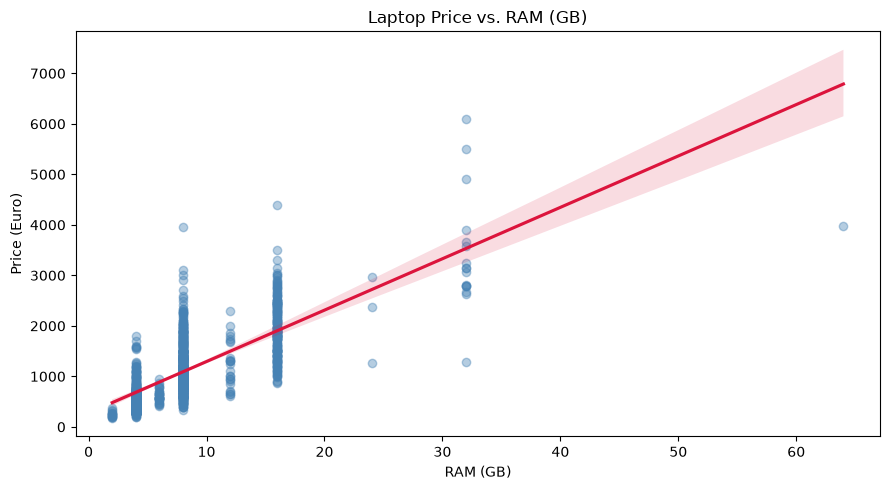

In [52]:
# C1. Relationship between RAM (GB) and Price (Euro)
# Check Pearson (linear) and Spearman (monotonic) correlations across all laptops
pearson_r = df["RAM (GB)"].corr(df["Price (Euro)"], method="pearson")
spearman_r = df["RAM (GB)"].corr(df["Price (Euro)"], method="spearman")
print(f"Pearson correlation:  {pearson_r:.3f}")
print(f"Spearman correlation: {spearman_r:.3f}")

# Group by RAM size to see count, mean price, and median price for each RAM level
ram_summary = (
    df.groupby("RAM (GB)")["Price (Euro)"]
    .agg(Count="count", Mean_Price="mean", Median_Price="median")
    .round(1)
)
display(ram_summary)

# Plot scatter points for all laptops + a linear trendline
fig, ax = plt.subplots(figsize=(9, 5))
# sns.regplot draws all three together: scatter points, trendline, and 95% confidence band
sns.regplot(
    data=df,
    x="RAM (GB)",
    y="Price (Euro)",
    scatter_kws={"alpha": 0.4, "color": "steelblue"},  # Transparency helps see overlapping points
    line_kws={"color": "crimson"},
    ax=ax,
)
ax.set_title("Laptop Price vs. RAM (GB)")
ax.set_xlabel("RAM (GB)")
ax.set_ylabel("Price (Euro)")

plt.tight_layout()
plt.savefig("figures/q2_ram_vs_price.png", dpi=150)  # Save image for submission
plt.show()

Question 2: How does screen size relate to laptop weight?

1. Why it is interesting:
Buyers often have to choose between a bigger screen and carrying the laptop easily, so it helps to see how much extra weight comes with a larger screen.

2. Relevant variables and observations:
I used Inches and Weight (kg) across all laptops, noting that most laptops cluster at a few standard screen sizes while some sizes have very few models.

3. Analytical method:
I calculated Pearson and Spearman correlations and summarized mean and median weights for each screen size.

4. Visualization:
The scatter plot with a trendline above shows the positive relationship between screen size and weight, as well as the weight spread at larger screen sizes.

5. Interpretation:
Screen size and weight have a strong positive relationship: larger screens consistently come with heavier laptops. At larger screen sizes, weight still varies a lot depending on the laptop type (like a thin laptop vs. a heavy gaming laptop).

Pearson correlation:  0.827
Spearman correlation: 0.879


,Count,Mean_Weight,Median_Weight
Inches,,,
10.1,4,0.69,0.69
11.3,1,1.10,1.10
11.6,31,1.29,1.25
12.0,6,0.92,0.92
12.3,5,1.17,1.10
12.5,39,1.29,1.26
13.0,2,1.05,1.05
13.3,160,1.33,1.31
13.5,6,1.25,1.25


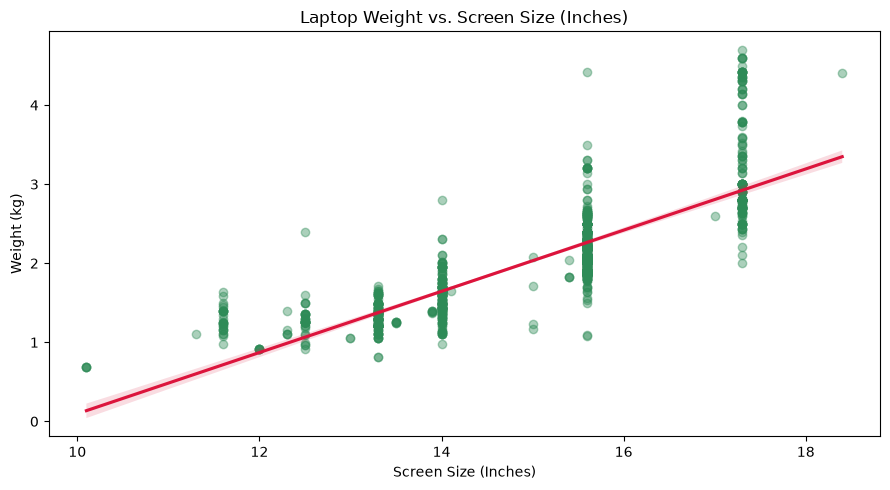

In [53]:
# C2. Relationship between screen size (Inches) and Weight (kg)
pearson_iw = df["Inches"].corr(df["Weight (kg)"], method="pearson")
spearman_iw = df["Inches"].corr(df["Weight (kg)"], method="spearman")
print(f"Pearson correlation:  {pearson_iw:.3f}")
print(f"Spearman correlation: {spearman_iw:.3f}")

# Group by screen size to see count, mean weight, and median weight
inches_summary = (
    df.groupby("Inches")["Weight (kg)"]
    .agg(Count="count", Mean_Weight="mean", Median_Weight="median")
    .round(2)
)
display(inches_summary)

# sns.regplot draws all three together: scatter points, trendline, and 95% confidence band
fig, ax = plt.subplots(figsize=(9, 5))
sns.regplot(
    data=df,
    x="Inches",
    y="Weight (kg)",
    scatter_kws={"alpha": 0.4, "color": "seagreen"},
    line_kws={"color": "crimson"},
    ax=ax,
)
ax.set_title("Laptop Weight vs. Screen Size (Inches)")
ax.set_xlabel("Screen Size (Inches)")
ax.set_ylabel("Weight (kg)")

plt.tight_layout()
plt.savefig("figures/q2_inches_vs_weight.png", dpi=150)  # Save image for submission
plt.show()

-------------------------------
Question 3: How are laptop prices distributed across the market?

1. Why it is interesting:
Before comparing specific specs, a buyer needs to know what a typical laptop costs and whether prices are spread evenly or pulled up by very expensive models.

2. Relevant variables and observations:
This analysis uses Price (Euro) across all laptops in the dataset.

3. Analytical method:
Summary statistics (mean, median, quartiles, and skewness) were computed to check the center, spread, and symmetry of prices.

4. Visualization:
The histogram above shows how many laptops fall into each price range, with vertical lines marking the median and the mean.

5. Interpretation:
Laptop prices are clearly right-skewed (positive skewness), with a long tail of very expensive models stretching to the right. Most laptops sit in the lower-to-mid price range, and the few very expensive models pull the mean above the median, so the median gives a better picture of a typical laptop price.


count    1275.00
mean     1134.97
std       700.75
min       174.00
25%       609.00
50%       989.00
75%      1496.50
max      6099.00
Name: Price (Euro), dtype: float64
Skewness: 1.51


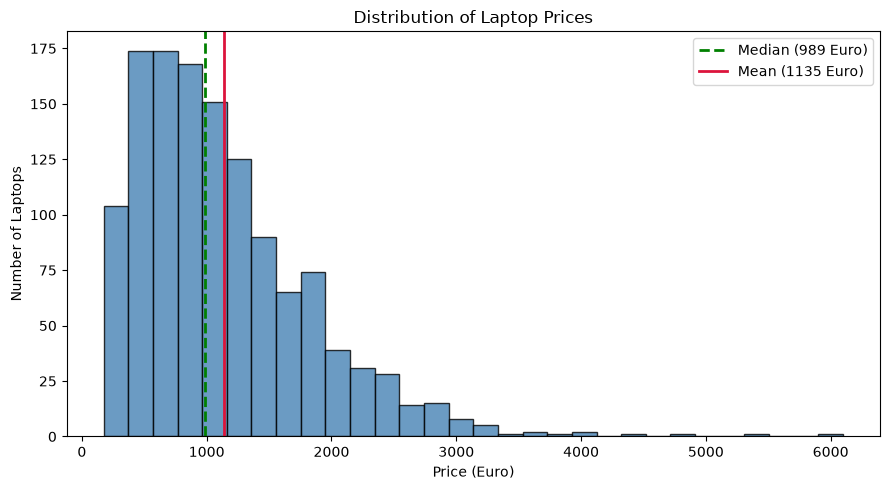

In [54]:
# C3. Investigating the distribution of laptop prices

# Compute summary stats (count, mean, std, min, quartiles, max) rounded to 2 decimals
price_stats = df["Price (Euro)"].describe().round(2)
print(price_stats)

# Check if prices are symmetric (0 = balanced, > 0 = long tail of high values, < 0 = long tail of low values)
print(f"Skewness: {df['Price (Euro)'].skew():.2f}")  # Format to 2 decimal places

# Create the histogram plot
fig, ax = plt.subplots(figsize=(9, 5))

# Group prices into 30 equal bins with black borders and slight transparency (alpha=0.8)
ax.hist(df["Price (Euro)"], bins=30, color="steelblue", edgecolor="black", alpha=0.8)

# Calculate mean and median so I can mark them on the histogram
mean_p = df["Price (Euro)"].mean()
median_p = df["Price (Euro)"].median()

# Draw vertical lines: dashed green for median, solid red for mean (rounded to whole Euros with :.0f)
ax.axvline(median_p, color="green", linestyle="--", linewidth=2, label=f"Median ({median_p:.0f} Euro)")
ax.axvline(mean_p, color="crimson", linestyle="-", linewidth=2, label=f"Mean ({mean_p:.0f} Euro)")

ax.set_title("Distribution of Laptop Prices")
ax.set_xlabel("Price (Euro)")
ax.set_ylabel("Number of Laptops")
ax.legend()  # Show the legend box for the mean and median lines

plt.tight_layout()  # Adjust spacing so labels do not get cut off
plt.savefig("figures/q2_price_distribution.png", dpi=150)  # Save image for submission
plt.show()

----------------------------
D. Investigating Unusual Observations (Outliers)

1. Definition and method:
An outlier is an observation that sits far away from most of the data. I used the standard IQR method on Price (Euro), flagging laptops priced above Q3 + 1.5 * IQR as high-price outliers.

2. Are these outliers errors?
No. Checking all 28 flagged laptops shows they are real high-end Gaming, Workstation, and premium Ultrabook models with strong specs (high RAM and SSD storage), not price errors. Even the very expensive ThinkPad P51 labeled as a Notebook is a real workstation-level laptop with high-end specs, not a mistake.

3. Effect of outliers and decision:
As shown in the comparison table above, excluding the outliers noticeably lowers the mean price and slightly reduces the Pearson correlation, while the median price and Spearman correlation barely change. Because all 28 laptops are real market options and the main conclusions stay the same with or without them, I decided to keep them in the dataset.

In [55]:
# D. Step 1: Identify price outliers using the IQR (Interquartile Range) method

# Q1 is the 25th percentile, Q3 is the 75th percentile
q1 = df["Price (Euro)"].quantile(0.25)
q3 = df["Price (Euro)"].quantile(0.75)
iqr = q3 - q1  # Spread of the middle 50% of prices

# Standard IQR rule: values above Q3 + 1.5 * IQR are flagged as high outliers
upper_bound = q3 + 1.5 * iqr

# Split the data into outliers vs. non-outliers (without deleting anything from df)
outliers = df[df["Price (Euro)"] > upper_bound]
df_no_outliers = df[df["Price (Euro)"] <= upper_bound]

print(f"Upper IQR bound: {upper_bound:.2f} Euro")
print(f"Number of price outliers: {len(outliers)} ({len(outliers) / len(df) * 100:.1f}%)")

# Look at all price outliers to check if any are data errors or all are real high-end models
print("\nAll price outliers (sorted by price):")
all_outliers = outliers.sort_values("Price (Euro)", ascending=False)[
    ["Company", "Product", "TypeName", "RAM (GB)", "Memory", "Price (Euro)"]
]
display(all_outliers)

Upper IQR bound: 2827.75 Euro
Number of price outliers: 28 (2.2%)

All price outliers (sorted by price):


,Company,Product,TypeName,RAM (GB),Memory,Price (Euro)
196,Razer,Blade Pro,Gaming,32,1TB SSD,6099.00
830,Razer,Blade Pro,Gaming,32,512GB SSD,5499.00
610,Lenovo,Thinkpad P51,Notebook,32,1TB SSD,4899.00
749,HP,Zbook 17,Workstation,16,256GB SSD,4389.00
1066,Asus,ROG G701VO,Gaming,64,1TB SSD,3975.00
1136,HP,ZBook 17,Workstation,8,256GB SSD,3949.40
238,Asus,ROG G703VI-E5062T,Gaming,32,512GB SSD + 1TB HDD,3890.00
723,Dell,Alienware 17,Gaming,32,1TB SSD + 1TB HDD,3659.40
780,Dell,Alienware 17,Gaming,32,1TB SSD + 1TB HDD,3588.80
1231,Razer,Blade Pro,Gaming,16,1TB SSD,3499.00


In [56]:
# D. Step 2: Compare Mean, Median, and RAM-Price correlations with vs. without price outliers

# Build a comparison table using df (all laptops) vs. df_no_outliers (excluding the 28 outliers)
comparison = pd.DataFrame({
    "Metric": [
        "Mean Price (Euro)",
        "Median Price (Euro)",
        "Pearson r (RAM vs Price)",
        "Spearman r (RAM vs Price)",
    ],
    "With Outliers": [
        round(df["Price (Euro)"].mean(), 2),
        round(df["Price (Euro)"].median(), 2),
        round(df["RAM (GB)"].corr(df["Price (Euro)"], method="pearson"), 3),
        round(df["RAM (GB)"].corr(df["Price (Euro)"], method="spearman"), 3),
    ],
    "Without Outliers": [
        round(df_no_outliers["Price (Euro)"].mean(), 2),
        round(df_no_outliers["Price (Euro)"].median(), 2),
        round(df_no_outliers["RAM (GB)"].corr(df_no_outliers["Price (Euro)"], method="pearson"), 3),
        round(df_no_outliers["RAM (GB)"].corr(df_no_outliers["Price (Euro)"], method="spearman"), 3),
    ],
})

display(comparison)

,Metric,With Outliers,Without Outliers
0,Mean Price (Euro),1134.970,1081.850
1,Median Price (Euro),989.000,977.000
2,Pearson r (RAM vs Price),0.740,0.711
3,Spearman r (RAM vs Price),0.764,0.753


---------------------------
E. Scientific Interpretation and Analytical Report

1. What was observed:
- Market prices (see figures/q2_price_distribution.png): Across the 1,275 laptops, prices are right-skewed (skewness = 1.51), with a median of 989 Euro and a mean of 1,135 Euro. Using the IQR rule, 28 laptops (2.2%) were flagged as high-price outliers (above 2,828 Euro), all of which are real high-end Gaming, Workstation, or premium Ultrabook models.
- RAM and price (see figures/q2_ram_vs_price.png): Higher RAM is strongly associated with higher prices (Pearson r = 0.740, Spearman r = 0.764). Excluding the 28 price outliers barely changes this trend (Pearson r = 0.711, Spearman r = 0.753).
- Screen size and weight (see figures/q2_inches_vs_weight.png): Larger screens are strongly associated with heavier laptops, though weight still varies within the larger screen sizes.

2. What the analysis supports:
- For someone shopping for a laptop, the median price (~989 Euro) is a much better benchmark for a typical laptop than the mean, because a few very expensive models pull the mean upward.
- Higher RAM is a reliable indicator of a higher price tier, and choosing a larger screen generally means carrying a heavier laptop.
- High-end outliers are legitimate market options, and the main trends hold whether they are included or excluded.

3. What cannot be concluded:
- Correlation does not prove causation. A strong link between RAM and price does not mean extra RAM alone causes the higher price—laptops with 16 or 32 GB RAM usually also come with faster CPUs, dedicated GPUs, and larger SSDs, which all raise the price together.
- Similarly, screen size alone does not determine weight, since laptop design (such as thin ultrabooks vs. gaming laptops) also plays a major role.

4. Limitations:
- The dataset is a single snapshot with no release dates, so prices may not reflect current market pricing.
- Each analysis looked at one feature at a time rather than separating the combined effects of CPU, GPU, brand, and RAM together.
- Very small sample sizes exist at the extremes (for example, only 1 laptop with 64 GB RAM and 3 with 24 GB RAM), so averages for those rare configurations are less reliable.